In [1]:
import sqlite3

import pandas as pd

## Data Loading
- Read the file from *breast_cancer.db* database using the *sqlite3.connect*.
- We can load the data using pandas and SQL queries. 
- Do a quickly visual check to see if the data is loaded correctly.
- Like use *df.head(no. of columns), df.info()*
- For null checking: *df.isnull().sum(), df.isnull.mean()*100*
- Also we can plot graphs like *df.[target_var] vs df.[first_var]*
- Check for **class impbalance**: *df["target_variable"].value_counts()*
- **bar plot** of target variable: *df["target_variable"].value_counts().plot(kind="bar")*
- Partial dependencies using **bar plot**: *pd.crosstab(df["variable_1"], df["target_variable"]).plot(kind="bar")*
- **Histograms** to check Relationships between a variable and a given class
    *df[df["target_varible"]==0]["var_1"].hist(alpha=0.5, bins=30, label="class_0")*
    *df[df["target_variable"]==1]["var_1"].hist(alpha=0.5, bins=30, label="class_1")*

In [2]:
import matplotlib.pyplot as plt

In [3]:
# Connect to the database
conn = sqlite3.connect("breast_cancer.db")

In [4]:
# Read the dataset
query = "SELECT * FROM breast_cancer"
df    = pd.read_sql_query(query, conn)

In [5]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [7]:
print("Shape of the dataset: {}".format(df.shape))

Shape of the dataset: (569, 31)


In [8]:
df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Text(0, 0.5, 'Count')

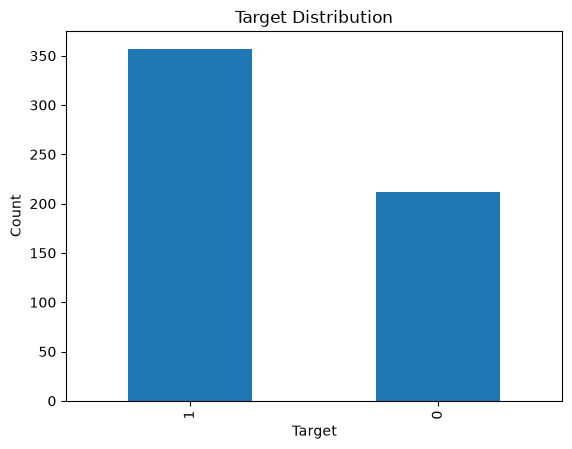

In [9]:
df["target"].value_counts().plot(kind="bar")
plt.title("Target Distribution")
plt.xlabel("Target")
plt.ylabel("Count")

In [10]:
df.columns.tolist()

['mean radius',
 'mean texture',
 'mean perimeter',
 'mean area',
 'mean smoothness',
 'mean compactness',
 'mean concavity',
 'mean concave points',
 'mean symmetry',
 'mean fractal dimension',
 'radius error',
 'texture error',
 'perimeter error',
 'area error',
 'smoothness error',
 'compactness error',
 'concavity error',
 'concave points error',
 'symmetry error',
 'fractal dimension error',
 'worst radius',
 'worst texture',
 'worst perimeter',
 'worst area',
 'worst smoothness',
 'worst compactness',
 'worst concavity',
 'worst concave points',
 'worst symmetry',
 'worst fractal dimension',
 'target']

<function matplotlib.pyplot.show(close=None, block=None)>

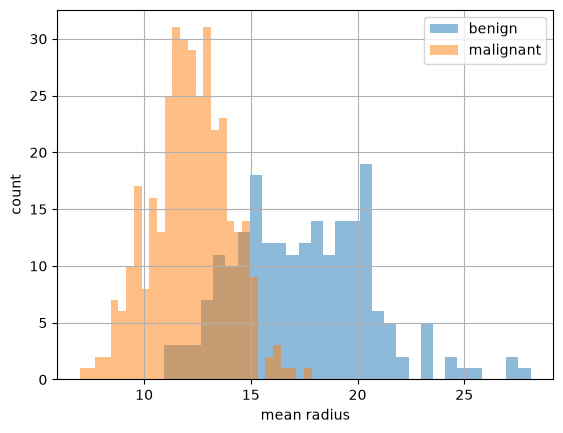

In [11]:
df[df["target"]==0]["mean radius"].hist(alpha=0.5, bins=30, label="benign")
df[df["target"]==1]["mean radius"].hist(alpha=0.5, bins=30, label="malignant")
plt.xlabel("mean radius")
plt.ylabel("count")
plt.legend()
plt.show

### Training Set 

*Create raw training set from data frame* <br>
- X (569, 30) <br>
- y (569, ) <br>

*Do the test train split* <br>
- Use scikit-learn to do this

In [12]:
# creating X and y variables
X = df.drop(columns=["target"])
y = df["target"]

print("Shape of input variables X: {}".format(X.shape))
print("Shape of output variable y: {}".format(y.shape))

Shape of input variables X: (569, 30)
Shape of output variable y: (569,)


In [13]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y,
                                                    stratify= y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    )

# Check the shape of the variables
print("The shape of the X_train: {}".format(X_train.shape))
print("The shape of the X_test: {}".format(X_test.shape))
print("The shape of the y_train: {}".format(y_train.shape))
print("The shape of the y_test: {}".format(y_test.shape))

The shape of the X_train: (455, 30)
The shape of the X_test: (114, 30)
The shape of the y_train: (455,)
The shape of the y_test: (114,)


### Data Preprocessing and Train the model
- Use scikit learn functions to train the model

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [16]:
standard = StandardScaler()
X_train = standard.fit_transform(X_train)

model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

### Model Evaluation
- Transform the test dataset
- Use the trained model to evaluate
- Plot the recall, precision, f1 score

In [17]:
from sklearn.metrics import recall_score, precision_score, f1_score

In [18]:
X_test = standard.transform(X_test)

y_predicted = model.predict(X_test)

In [21]:
# Evaluate the metrics for benign classification

r_score = recall_score(y_test, y_predicted)
p_score = precision_score(y_test, y_predicted)
f1 = f1_score(y_test, y_predicted) 

print("Recall for malignant tumors: {}".format(r_score))
print("Precision in predicting malignant tumors: {}".format(p_score))
print("F1 score of the model: {}".format(f1))

Recall for malignant tumors: 0.9859154929577465
Precision in predicting malignant tumors: 0.9722222222222222
F1 score of the model: 0.9790209790209791


In [22]:
# Evaluate the metrics for a specific class
# Lets say, malignant class, which is 0
# we use pos_label parameter 
r_score = recall_score(y_test, y_predicted, pos_label=0)
p_score = precision_score(y_test, y_predicted, pos_label=0)
f1 = f1_score(y_test, y_predicted, pos_label=0)

print("Recall for malignant tumors: {}".format(r_score))
print("Precision in predicting malignant tumors: {}".format(p_score))
print("F1 score of the model: {}".format(f1))

Recall for malignant tumors: 0.9534883720930233
Precision in predicting malignant tumors: 0.9761904761904762
F1 score of the model: 0.9647058823529412
